# Some parameters

In [ ]:
#constant values used all over the code

EPOCHS = 10
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)
IMAGE_SIZE_C = (224, 224, 3) #same as image size, but with the channels
LOCAL_DIR = "./ants_bees"


# Download the data

In [ ]:
from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="ggsmith/Hymenoptera",
    repo_type="dataset",
    local_dir=LOCAL_DIR
)

print(dataset_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 400 files:   0%|          | 0/400 [00:00<?, ?it/s]

/content/ants_bees


We expect this final folder structure:

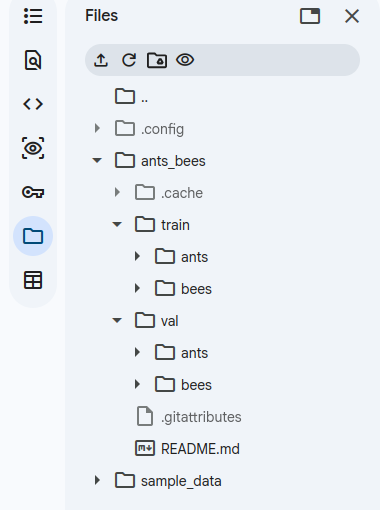

Containing these kind of images:

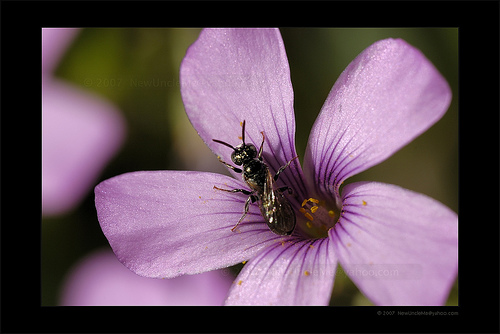

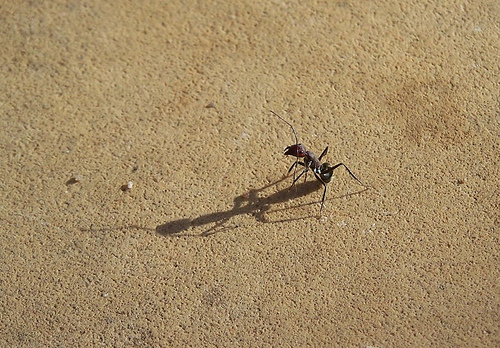

# Setup the data loaders

In [ ]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    LOCAL_DIR + "/train",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    LOCAL_DIR + "/val",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

Found 245 files belonging to 2 classes.
Found 153 files belonging to 2 classes.


# MODEL 1) A naive Convolutional Neural Network

## Define the network

In [ ]:
from keras import models, layers
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

#the architecture
model = models.Sequential()
model.add(Input(IMAGE_SIZE_C))

#basic data augmentation
model.add(layers.RandomFlip("horizontal"))
model.add(layers.RandomRotation(0.1))

#the conv network
model.add(Conv2D(filters=32, kernel_size=(3, 3), strides=1, padding="same", activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(64, (3, 3), padding="same", activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(128, (3, 3), padding="same", activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))

#the head for binary classification
model.add(Flatten())
model.add(Dense(units=1, activation='sigmoid'))

#compile
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

#let's take a look
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │       100,353 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193,601 (756.25 KB)

 Trainable params: 193,601 (756.25 KB)

 Non-trainable params: 0 (0.00 B)

## Train the naive model

In [ ]:
h = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds, verbose = 1)


Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 34s 4s/step - accuracy: 0.4735 - loss: 90.2864 - val_accuracy: 0.5229 - val_loss: 4.5064
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 39s 4s/step - accuracy: 0.5592 - loss: 3.1239 - val_accuracy: 0.6209 - val_loss: 0.9379
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 47s 5s/step - accuracy: 0.6571 - loss: 0.7439 - val_accuracy: 0.6667 - val_loss: 0.6702
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.6286 - loss: 0.6327 - val_accuracy: 0.5686 - val_loss: 0.7139
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 43s 4s/step - accuracy: 0.6612 - loss: 0.6120 - val_accuracy: 0.6405 - val_loss: 0.6775
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 37s 5s/step - accuracy: 0.6857 - loss: 0.5601 - val_accuracy: 0.6340 - val_loss: 0.6835
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 33s 4s/step - accuracy: 0.6939 - loss: 0.5503 - val_accuracy: 0.6863 - val_loss: 0.6600
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 33s 4s/step - accuracy: 0.7143 - loss: 0.5409 - val_accuracy: 0.7059 - val_loss: 0.6183
Epoch 9

# MODEL2) Keras application (MobileNetV2)

In [ ]:
from tensorflow import keras

MobNet = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False, #chopping away the final part
    input_shape=IMAGE_SIZE_C
)

#we want to make sure that the network is frozen
MobNet.trainable = False

#taking a look
MobNet.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

Note the final output shape: 7 x 7 x 1280. The data "face" is very small, passing from the original 224x224 to a 7x7. The number of channels (the "thickness") is very high, 1280.

The next block adds some preprocessing (data augmentation, mobilenet-specific preprocessing) and the classification head. Note the use of [GlobalAveragePooling2D()](https://keras.io/api/layers/pooling_layers/global_average_pooling2d/9) instead of [Flatten()](https://keras.io/api/layers/reshaping_layers/flatten/). This is because a simple Flatten would create a vector of 7x7x1280=62720 elements, each to be fed to the output layer.

In [ ]:
model2 = models.Sequential()

#the input
model2.add(Input(IMAGE_SIZE_C))

#adding data augmentation
model2.add(layers.RandomFlip("horizontal"))
model2.add(layers.RandomRotation(0.1))

#MobileNetV2-specific preprocessing function. I need to wrap it into a
#lambda since it's not formally a layer and thus cannot be added to a model
model2.add( keras.layers.Lambda(keras.applications.mobilenet_v2.preprocess_input))

#adding the model
model2.add(MobNet)

#new classification head. Flatten would create a huuuuge vector for the
#dense part. We shrink the features further with GAP
model2.add(layers.GlobalAveragePooling2D())
model2.add(layers.Dropout(0.2))

#output for binary classification
model2.add(layers.Dense(1, activation="sigmoid"))

#done building, let's compile and take a look
model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001), #LR=0.001 is the default value
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Train the transferred model

In [ ]:
h2 = model2.fit(train_ds, epochs=EPOCHS, validation_data=val_ds, verbose = 1)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.6612 - loss: 0.5923 - val_accuracy: 0.8235 - val_loss: 0.4409
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.8449 - loss: 0.3911 - val_accuracy: 0.9216 - val_loss: 0.2960
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.8980 - loss: 0.2944 - val_accuracy: 0.9412 - val_loss: 0.2341
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.9429 - loss: 0.2253 - val_accuracy: 0.9281 - val_loss: 0.1961
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.9265 - loss: 0.1906 - val_accuracy: 0.9412 - val_loss: 0.1857
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.9388 - loss: 0.1856 - val_accuracy: 0.9346 - val_loss: 0.1615
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.9633 - loss: 0.1358 - val_accuracy: 0.9346 - val_loss: 0.1518
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.9592 - loss: 0.1235 - val_accuracy: 0.9346 - val_loss: 0.1454
Epoch 9/

# Fine tuning

As a demo, out of the ~100 layers of MobileNet, we taw the last 30. Let's see what happens to the number of parameters.

In [ ]:
#unfreeze (taw) the pretrained network
MobNet.trainable = True

#freeze all but the last 30 layers (of 105)
for layer in MobNet.layers[:-30]:
    layer.trainable = False

#keep BatchNormalization layers frozen
for layer in MobNet.layers[-30:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

#recompile with a much smaller learning rate
model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5), #default is 1e-3
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

#let's take a look at the model now
model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,512,001 (5.77 MB)

 Non-trainable params: 747,264 (2.85 MB)

Training with fine tuning!

In [ ]:
#training again
h2_finetune = model2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.9592 - loss: 0.1243 - val_accuracy: 0.9412 - val_loss: 0.1268
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9714 - loss: 0.0975 - val_accuracy: 0.9281 - val_loss: 0.1371
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9755 - loss: 0.0938 - val_accuracy: 0.9346 - val_loss: 0.1153
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9837 - loss: 0.0781 - val_accuracy: 0.9412 - val_loss: 0.1144
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.9837 - loss: 0.0515 - val_accuracy: 0.9412 - val_loss: 0.1134
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.9878 - loss: 0.0685 - val_accuracy: 0.9477 - val_loss: 0.1106
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9918 - loss: 0.0499 - val_accuracy: 0.9412 - val_loss: 0.1128
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 1.0000 - loss: 0.0262 - val_accuracy: 0.9412 - val_loss: 0.1081
Epoch 9/

# MODEL 3) External model (Vision Transformer from Hugging Face)


A vision transformer architecture from Hugging Face. We implemented it into another notebook because of installation/library version issues.